# Familia girasol: osciladores separados por el ángulo áureo

**Dirección A** de la competencia: buscar grafos densos con trampas (mínimos locales estrictos de la
energía que no son el estado sincronizado). Antes de intentar subir la cota, los mentores sugirieron
elegir **una familia** y analizarla a fondo. Este notebook estudia la familia del **girasol**.

## Motivación

En un girasol, la semilla $v$ está girada $v\gamma$ respecto de la primera, con
$\gamma = 2\pi/\varphi^2 \approx 137.5^\circ$ el **ángulo áureo** y $\varphi = (1+\sqrt5)/2$. Ese ángulo
reparte las semillas lo más parejo posible, y produce las famosas espirales: los vecinos visuales de
una semilla están a distancias de índice 1, 2, 3, 5, 8, 13, … (números de Fibonacci).

Lo llevamos al círculo de fases: el oscilador $v$ ocupa la posición $x_v = v/\varphi \bmod 1$ (usar
$1/\varphi$ o $1/\varphi^2$ da lo mismo salvo la reflexión $\theta \to -\theta$, que es una simetría de
la energía) y se unen los osciladores cercanos. Estudiamos tres variantes:

| variante | grafo | resultado |
|---|---|---|
| 1 | circulantes $C_{F_k}(S)$ con $S$ ⊂ distancias de Fibonacci | **demostrado**: $\mu \le 0.6838$; en la práctica $\mu \to 0$ |
| 2 | grafo geométrico sobre $x_v = v/\varphi$, con radio $r$ | $n$ Fibonacci: **demostrado** que es un anillo $C_{n,\rho}$; $n$ no Fibonacci: peor que el anillo |
| 3 | plantillas con clusters en las fases áureas | numérico: $\le 0.679$, debajo de 0.6838 |

Spoiler: la familia **no supera las cotas conocidas** (11/16 de Canale, 0.6929 de O'Keeffe), pero
casi todo se puede explicar con teoría de números, y eso responde con precisión *por qué* no alcanza.

**Colab.** Este notebook usa `src/` y `data/` del repo, que es privado. En Colab, la celda de abajo lo clona usando un token de GitHub guardado en los Secrets (ícono de la llave, nombre `GITHUB_TOKEN`, con "Notebook access" activado); en local no hace nada. Para traer cambios nuevos: `!git -C /content/investighaton-teo-optimizacion-2026 pull`.

In [1]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
CARPETA_REPO = "/content/investighaton-teo-optimizacion-2026"

if EN_COLAB:
    if not os.path.exists(CARPETA_REPO):
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        !git clone -q https://{token}@github.com/Nicoyanz98/investighaton-teo-optimizacion-2026.git {CARPETA_REPO}
    %cd {CARPETA_REPO}/notebooks
    !pip install -q -r requirements.txt

In [2]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt

from src.aurea import (PHI, distancias_fibonacci, estado_aureo, fibonacci, multiplicar_conjunto,
                       puntos_aureos, simetrizar, trampa_geometrica)
from src.busqueda import red_aurea, sdp_interno, una_red
from src.experimentos import cargar_json, silenciar_avisos
from src.grafos import grafo_circulante, grafo_circulante_conjunto, grafo_geometrico_circular
from src.kuramoto import autovalores_twisted_conjunto, hessiano, twisted_state, velocidad

silenciar_avisos()
plt.rcParams["figure.dpi"] = 110

## 0. El girasol y su versión en el círculo

A la izquierda, el girasol de Vogel: la semilla $v$ en radio $\sqrt v$ y ángulo $v\gamma$. Se ven las
espirales; con colores, las semillas a distancia de índice 21 y 34. A la derecha, lo que usamos: solo
el ángulo, es decir, los puntos $x_v = v/\varphi \bmod 1$ sobre el círculo.

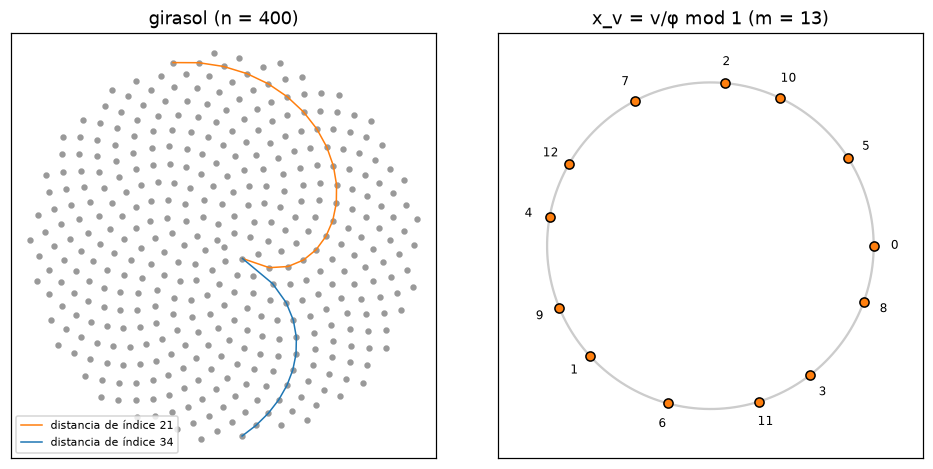

In [3]:
n = 400
v = np.arange(n)
angulo = 2 * np.pi * v / PHI**2
radio = np.sqrt(v)

fig, ejes = plt.subplots(1, 2, figsize=(9, 4.3))
ejes[0].scatter(radio * np.cos(angulo), radio * np.sin(angulo), s=10, color="0.6")
for paso, color in [(21, "tab:orange"), (34, "tab:blue")]:
    cadena = np.arange(5, n, paso)
    ejes[0].plot(radio[cadena] * np.cos(angulo[cadena]), radio[cadena] * np.sin(angulo[cadena]),
                 color=color, lw=1, label=f"distancia de índice {paso}")
ejes[0].set(aspect="equal", xticks=[], yticks=[], title="girasol (n = 400)")
ejes[0].legend(fontsize=7, loc="lower left")

m = 13
x = puntos_aureos(m)
s = np.linspace(0, 2 * np.pi, 200)
ejes[1].plot(np.cos(s), np.sin(s), color="0.8")
ejes[1].scatter(np.cos(2 * np.pi * x), np.sin(2 * np.pi * x), color="tab:orange", edgecolor="k", zorder=3)
for indice in range(m):
    ejes[1].annotate(str(indice), (1.13 * np.cos(2 * np.pi * x[indice]), 1.13 * np.sin(2 * np.pi * x[indice])),
                     ha="center", va="center", fontsize=8)
ejes[1].set(aspect="equal", xticks=[], yticks=[], xlim=(-1.3, 1.3), ylim=(-1.3, 1.3),
            title="x_v = v/φ mod 1 (m = 13)")
plt.tight_layout()
plt.show()

En el círculo de la derecha, los vecinos de cada punto tienen índices que difieren en un número de
Fibonacci (por ejemplo, 0 y 8, 0 y 5). Eso tiene una explicación exacta (Lema 3).

## 1. Notación y la herramienta básica: twisted states en circulantes

- $F_1 = F_2 = 1$, $F_{j+1} = F_j + F_{j-1}$.
- Para $S \subset \mathbb Z_n$ simétrico ($S = -S$, $0 \notin S$), el **circulante** $C_n(S)$ une
  $u \sim v$ si $v - u \in S \pmod n$. Su grado es $|S|$ y su conectividad $\mu = (|S|+1)/n$. El anillo
  de siempre es $C_{n,k} = C_n(\{\pm1, \dots, \pm k\})$.
- El **twisted state** de $q$ vueltas es $\theta^{(q)}_v = 2\pi q v/n$.
- $\mathbf 1^\perp$: todas las direcciones salvo la rotación global $\mathbf 1 = (1, \dots, 1)$.
  "Mínimo estricto" = Hessiano definido positivo en $\mathbf 1^\perp$.

**Lema 1.** $\theta^{(q)}$ es equilibrio de $C_n(S)$ y los autovalores de su Hessiano son
$$\lambda_m = \sum_{s \in S} \cos\!\left(\tfrac{2\pi q s}{n}\right)\left(1 - \cos\tfrac{2\pi m s}{n}\right), \qquad m = 0, \dots, n-1.$$

*Prueba.* La velocidad de $v$ es $\sum_{s\in S}\sin(2\pi qs/n) = 0$, porque $S = -S$ y el seno es
impar. El Hessiano tiene $H_{v,v+s} = -\cos(2\pi qs/n)$, que no depende de $v$: es una matriz
circulante, y la diagonalizan las ondas $e^{2\pi i mv/n}$. Su autovalor es
$\sum_s \cos(2\pi qs/n)(1 - e^{2\pi i ms/n})$, y la parte imaginaria se cancela agrupando $s$ con $-s$.
$\lambda_0 = 0$ es la rotación global. ∎

Verificación contra el Hessiano numérico:

In [4]:
n = 17
S = simetrizar([2, 5, 7], n)
W = grafo_circulante_conjunto(n, S)
for q in [1, 3, 6]:
    theta = twisted_state(n, q)
    numericos = np.sort(np.linalg.eigvalsh(hessiano(theta, W)))
    formula = np.sort(autovalores_twisted_conjunto(n, S, q))
    print(f"q = {q}:  ‖θ̇‖ = {np.linalg.norm(velocidad(theta, W)):.1e}   "
          f"máx |λ_numérico − λ_fórmula| = {np.abs(numericos - formula).max():.1e}")

q = 1:  ‖θ̇‖ = 2.7e-15   máx |λ_numérico − λ_fórmula| = 4.4e-15
q = 3:  ‖θ̇‖ = 2.5e-15   máx |λ_numérico − λ_fórmula| = 6.7e-15
q = 6:  ‖θ̇‖ = 9.2e-15   máx |λ_numérico − λ_fórmula| = 6.1e-15


## 2. Variante 1: circulantes de Fibonacci

Con $n = F_k$, la versión exacta (racional) de $v/\varphi$ es $v F_{k-1}/F_k$, así que el **estado
áureo** es el twisted state $q = F_{k-1}$. Unimos los osciladores a distancias de índice de Fibonacci,
como las espirales del girasol: $S \subset \{\pm F_j\}$.

**Lema 2 (multiplicadores).** Si $\mathrm{mcd}(q, n) = 1$, la biyección $\sigma(v) = qv \bmod n$ es un
isomorfismo $C_n(S) \to C_n(qS)$ que lleva $\theta^{(q)}$ a $\theta^{(1)}$.

*Prueba.* $\sigma$ es biyección porque $q$ es invertible mod $n$; preserva aristas porque
$v - u \in S \iff \sigma(v) - \sigma(u) \in qS$; y $2\pi qv/n \equiv 2\pi\sigma(v)/n \pmod{2\pi}$.
Energía y Hessiano solo dependen de aristas y diferencias de fase, así que los espectros coinciden. ∎

**Lema 3 (las espirales).** Para $2 \le j < k$: $F_{k-1}F_j \equiv (-1)^{j-1}F_{k-j} \pmod{F_k}$.

*Prueba.* La identidad de d'Ocagne, $F_aF_{b+1} - F_{a+1}F_b = (-1)^bF_{a-b}$, con $a = k-1$ y
$b = j-1$, da $F_{k-1}F_j - F_kF_{j-1} = (-1)^{j-1}F_{k-j}$; se reduce mod $F_k$. ∎

Leído en el estado áureo: dos osciladores a distancia de índice $F_j$ tienen diferencia de fase
$2\pi F_{k-j}/F_k \approx 2\pi\varphi^{-j}$, que es chica. Por eso los vecinos visuales del girasol
están a distancias de Fibonacci.

**Proposición A.** $(C_{F_k}(S), \text{estado áureo}) \cong (C_{F_k}(S'), \theta^{(1)})$ con
$S' = \{\pm F_{k-j}\}$. Es el Lema 2 con $q = F_{k-1}$ (coprimo con $F_k$) más el Lema 3.

**Corolario.** Si el estado áureo es trampa estricta de $C_{F_k}(S)$, entonces $\mu$ está acotado por
el LP de twisted states $q = 1$ (Yoneda et al.), que da $\le 0.6838$. La variante 1 **no puede**
superar 11/16. (La prueba completa, con la factibilidad en el LP, está en `notes/familia_aurea.md`.)

Verificación del Lema 3 y de la Proposición A:

In [5]:
fallas = 0
for k in range(4, 41):
    for j in range(2, k):
        izquierda = (fibonacci(k - 1) * fibonacci(j)) % fibonacci(k)
        derecha = ((-1) ** (j - 1) * fibonacci(k - j)) % fibonacci(k)
        if izquierda != derecha:
            fallas += 1
print("Lema 3, k ≤ 40: fallas =", fallas)

k = 10
n = fibonacci(k)
q = fibonacci(k - 1)
S = simetrizar(distancias_fibonacci(k)[1:4], n)
S_prima = multiplicar_conjunto(S, q, n)
aureo = np.sort(autovalores_twisted_conjunto(n, S, q))
uno = np.sort(autovalores_twisted_conjunto(n, S_prima, 1))
print(f"Proposición A, n = {n}: S = {S[:len(S) // 2]} → S' = {S_prima[:len(S_prima) // 2]},  "
      f"máx diferencia de espectros = {np.abs(aureo - uno).max():.1e}")

Lema 3, k ≤ 40: fallas = 0
Proposición A, n = 55: S = [2, 3, 5] → S' = [5, 8, 13],  máx diferencia de espectros = 6.9e-14


**Resultados** (fuerza bruta sobre todos los $S$, `scripts/explorar_aurea.py`):

In [6]:
fibonacci_resultados = cargar_json("aurea_fibonacci.json")
print(f"{'k':>3} {'n':>5} {'μ máx':>7}  distancias óptimas")
for fila in fibonacci_resultados:
    print(f"{fila['k']:>3} {fila['n']:>5} {fila['mu']:7.4f}  {fila['distancias']}")

  k     n   μ máx  distancias óptimas
  5     5  0.6000  [2]
  6     8  0.6250  [2, 3]
  7    13  0.5385  [2, 3, 5]
  8    21  0.4286  [2, 3, 5, 8]
  9    34  0.3235  [2, 3, 5, 8, 13]
 10    55  0.2364  [2, 3, 5, 8, 13, 21]
 11    89  0.1685  [2, 3, 5, 8, 13, 21, 34]
 12   144  0.1181  [2, 3, 5, 8, 13, 21, 34, 55]
 13   233  0.0815  [2, 3, 5, 8, 13, 21, 34, 55, 89]
 14   377  0.0557  [2, 3, 5, 8, 13, 21, 34, 55, 89, 144]


- El óptimo siempre es **todas las distancias de Fibonacci salvo la 1**. Por la Proposición A eso es
  el estado $q = 1$ en $C_n(\{\pm1, \pm2, \pm3, \pm5, \dots, \pm F_{k-3}\})$: todas las diferencias de
  fase son $\le \varphi^{-3} \approx 0.24$ vuelta, todos los acoples tienen $\cos > 0$ y el Hessiano es
  un Laplaciano con pesos positivos. La distancia 1, en cambio, tiene diferencia de fase igual al
  ángulo áureo (137.5°, $\cos \approx -0.74$).
- Es **rala**: hay solo $\sim\log_\varphi n$ distancias de Fibonacci y $\mu = (2k-7)/F_k \to 0$.

## 3. Variante 2: el grafo geométrico áureo

Ahora $n$ cualquiera: puntos $x_v = v/\varphi \bmod 1$, arista si la distancia circular es $\le r$, y
estado inicial "fase = posición", $\theta_v = 2\pi x_v$.

**Proposición B.** Si $n = F_k$ y $r = (\rho + \tfrac12)/n$, el grafo es isomorfo a $C_{n,\rho}$ y el
estado áureo está a menos de $2\pi \cdot 0.45/n$ del twisted state $q = 1$.

*Idea de la prueba.* Por Binet, $1/\varphi = F_{k-1}/F_k + \varepsilon$ con
$|\varepsilon| = \varphi^{-k}/F_k$. Entonces $x_v$ es la "ranura" equiespaciada $s_v/n$
($s_v = vF_{k-1} \bmod F_k$, una permutación) más un corrimiento $v\varepsilon$ menor que
$\tfrac{1}{2n}$. Con $r$ a mitad de camino entre dos ranuras, el corrimiento no cambia ninguna
arista: en las etiquetas $s$ es exactamente $C_{n,\rho}$. ∎

Con $n$ de Fibonacci la variante 2 **es** la familia de anillos de Wiley–Strogatz–Girvan. Con $n$ no
Fibonacci el grafo deja de ser circulante. Por el teorema de las tres distancias (Steinhaus–Sós), los
huecos entre puntos vecinos toman 2 o 3 valores, y el estado áureo deja de ser un equilibrio exacto:
hay que relajarlo. Además la matriz de adyacencia es **Toeplitz**: la distancia entre $x_u$ y $x_v$
es $\|(u - v)/\varphi\|$, que depende solo de $u - v$.

n =  21:  grafo = C_(n,5) reetiquetado: True   máx desvío·n/2π = 0.426 < 0.45
n =  55:  grafo = C_(n,13) reetiquetado: True   máx desvío·n/2π = 0.439 < 0.45
n = 144:  grafo = C_(n,36) reetiquetado: True   máx desvío·n/2π = 0.444 < 0.45


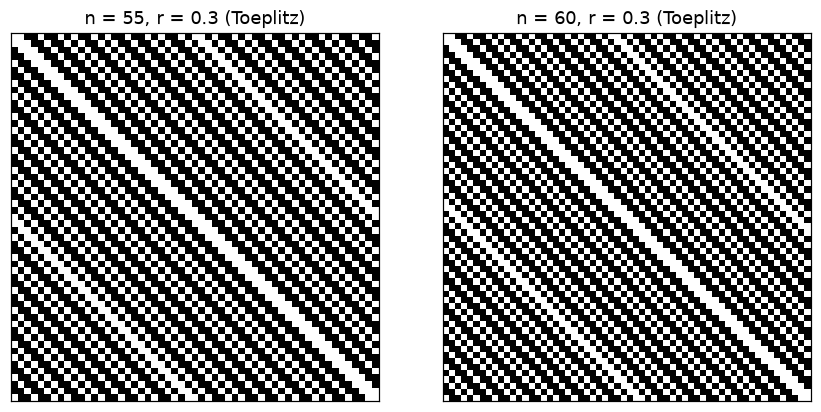

In [7]:
for k in [8, 10, 12]:
    n = fibonacci(k)
    ranura = (np.arange(n) * fibonacci(k - 1)) % n
    rho = n // 4
    W = grafo_geometrico_circular(puntos_aureos(n), (rho + 0.5) / n)
    igual = np.array_equal(W, grafo_circulante(n, rho)[np.ix_(ranura, ranura)])
    desvio = np.abs(np.angle(np.exp(1j * (estado_aureo(n) - 2 * np.pi * ranura / n)))).max()
    print(f"n = {n:3d}:  grafo = C_(n,{rho}) reetiquetado: {igual}   máx desvío·n/2π = {desvio * n / (2 * np.pi):.3f} < 0.45")

fig, ejes = plt.subplots(1, 2, figsize=(8, 3.8))
for eje, n in zip(ejes, [55, 60]):
    W = grafo_geometrico_circular(puntos_aureos(n), 0.3)
    eje.imshow(W, cmap="Greys")
    eje.set(title=f"n = {n}, r = 0.3 (Toeplitz)", xticks=[], yticks=[])
plt.tight_layout()
plt.show()

**Un ejemplo** con $n = 100$ (no Fibonacci): se relaja el estado áureo y se clasifica el equilibrio.

In [8]:
resultado = trampa_geometrica(100, 0.3)
for clave in ["n", "r", "mu", "tipo", "winding", "velocidad", "autovalor_min", "trampa"]:
    print(f"{clave:>14}: {resultado[clave]}")

             n: 100
             r: 0.3
            mu: 0.59
          tipo: mínimo estricto
       winding: 1
     velocidad: 4.8363581788076526e-14
 autovalor_min: 3.756543522883582
        trampa: True


**Barrido** $n = 8..200$: para cada $n$ se prueban todos los radios donde el grafo cambia y se toma el
mayor $\mu$ con trampa. Se compara con el mejor anillo del mismo $n$, $(2k_{\max}+1)/n$.

n Fibonacci: máx |μ_áureo − μ_anillo| = 0.0
n no Fibonacci: áureo mejor / igual / peor que el anillo: 0 1 185


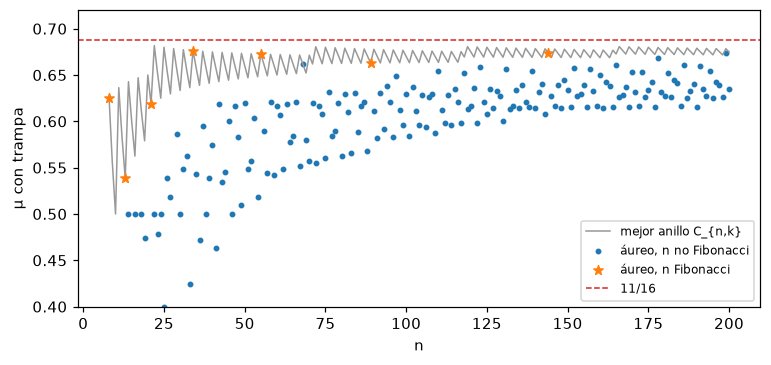

In [9]:
geometrico = cargar_json("aurea_geometrico.json")
ns = np.array([fila["n"] for fila in geometrico])
mu_aureo = np.array([fila["mu_aureo"] for fila in geometrico])
mu_anillo = np.array([fila["mu_anillo"] for fila in geometrico])
es_fib = np.array([fila["fibonacci"] for fila in geometrico])

print("n Fibonacci: máx |μ_áureo − μ_anillo| =", np.abs(mu_aureo - mu_anillo)[es_fib].max())
no_fib = ~es_fib
print("n no Fibonacci: áureo mejor / igual / peor que el anillo:",
      int(np.sum(mu_aureo[no_fib] > mu_anillo[no_fib] + 1e-12)),
      int(np.sum(np.abs(mu_aureo[no_fib] - mu_anillo[no_fib]) <= 1e-12)),
      int(np.sum(mu_aureo[no_fib] < mu_anillo[no_fib] - 1e-12)))

fig, eje = plt.subplots(figsize=(8, 3.5))
eje.plot(ns, mu_anillo, color="0.6", lw=1, label="mejor anillo C_{n,k}")
eje.scatter(ns[no_fib], mu_aureo[no_fib], s=8, color="tab:blue", label="áureo, n no Fibonacci")
eje.scatter(ns[es_fib], mu_aureo[es_fib], s=40, color="tab:orange", marker="*", label="áureo, n Fibonacci", zorder=3)
eje.axhline(11 / 16, color="tab:red", ls="--", lw=1, label="11/16")
eje.set(xlabel="n", ylabel="μ con trampa", ylim=(0.4, 0.72))
eje.legend(fontsize=8)
plt.show()

Los $n$ de Fibonacci caen exactamente sobre el anillo, como dice la Proposición B. Los $n$ no
Fibonacci quedan por debajo: los huecos desiguales que introducen las tres distancias **empeoran** la
trampa en vez de ayudarla.

## 4. Variante 3: plantillas en las fases áureas

A nivel de clusters (como en `Implementacion_papers.ipynb`): $m$ clusters en las fases
$\varphi_a = 2\pi a/\varphi$ con tamaños $x_a$. Con fases y tamaños fijos, el SDP `sdp_interno`
optimiza las densidades entre clusters y da el mayor $\mu$ con $L \succ 0$ en $\mathbf 1^\perp$. Se
prueban tres tipos de tamaños:
- **iguales**: $1/m$;
- **arcos**: cada cluster pesa el arco del círculo más cercano a él que a los demás (una celda de
  Voronoi), lo que compensa los huecos desiguales;
- **geométricos**: $\propto \varphi^{-a}$.

La referencia es el LP de twisted states (la red equiespaciada, Yoneda et al.). Un caso en vivo:

In [10]:
m = 15
mu_equi, _ = sdp_interno(*una_red(m), margen=1e-9, margen_c=1e-6)
print(f"red equiespaciada, m = {m}: μ = {mu_equi:.4f}")
for pesos in ["iguales", "arcos", "geometricos"]:
    mu, _ = sdp_interno(*red_aurea(m, pesos), margen=1e-9, margen_c=1e-6)
    print(f"red áurea {pesos:>11}, m = {m}: μ = {mu:.4f}")

red equiespaciada, m = 15: μ = 0.6708


red áurea     iguales, m = 15: μ = 0.6121
red áurea       arcos, m = 15: μ = 0.6743


red áurea geometricos, m = 15: μ = 0.3185


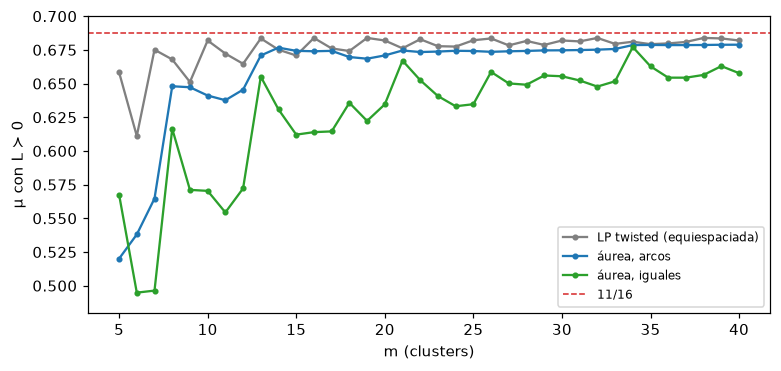

mejor plantilla áurea: μ = 0.6788 (arcos, m = 40);  mejor twisted: 0.6839


In [11]:
plantillas = cargar_json("aurea_plantillas.json")
ms = np.array([fila["m"] for fila in plantillas])

fig, eje = plt.subplots(figsize=(8, 3.5))
eje.plot(ms, [fila["twisted_lp"] for fila in plantillas], "o-", color="0.5", ms=3, label="LP twisted (equiespaciada)")
eje.plot(ms, [fila["arcos"] for fila in plantillas], "o-", color="tab:blue", ms=3, label="áurea, arcos")
eje.plot(ms, [fila["iguales"] for fila in plantillas], "o-", color="tab:green", ms=3, label="áurea, iguales")
eje.axhline(11 / 16, color="tab:red", ls="--", lw=1, label="11/16")
eje.set(xlabel="m (clusters)", ylabel="μ con L ≻ 0", ylim=(0.48, 0.70))
eje.legend(fontsize=8)
plt.show()

mejor = max(plantillas, key=lambda fila: fila["arcos"])
print(f"mejor plantilla áurea: μ = {mejor['arcos']:.4f} (arcos, m = {mejor['m']});  "
      f"mejor twisted: {max(fila['twisted_lp'] for fila in plantillas):.4f}")

- Los pesos "arcos" son los buenos y se acercan a la red equiespaciada al crecer $m$, pero sin
  superar al mejor twisted (0.6838).
- En $m = 14, 15$ la red áurea le gana a la equiespaciada **del mismo** $m$, solo porque esos $m$ son
  malos para twisted.
- Los pesos geométricos dan $\approx 0.32$: el primer cluster se lleva casi todo el peso.

## 5. Conclusión

- La familia girasol **no da trampas más densas** que las conocidas. Las variantes 1 y 2 (con $n$
  Fibonacci) se reducen, por teoría de números, a twisted states $q = 1$ en circulantes, acotados por
  0.6838. Lo que no se reduce queda numéricamente por debajo.
- **Por qué no alcanza:** la virtud del ángulo áureo es repartir los puntos lo más parejo posible.
  Pero eso tiende a la distribución uniforme en el círculo, el mismo límite que los anillos
  ($\mu \to 0.681$). Los récords (Canale, O'Keeffe) hacen lo contrario: concentran los osciladores en
  **pocos clusters** muy desparejos.
- Lo valioso es que es una familia con fórmulas cerradas y pruebas completas, y que la conexión entre
  las espirales del girasol y el isomorfismo con $q = 1$ explica exactamente su comportamiento.